# 설명 가능한 인공지능(XAI)

- XAI(Explainable AI)는 인간이 이해할 수 있는 방식으로 인공지능 모델의 의사결정 과정을 설명해주는 기술 및 접근 방식

- 목표
    - AI의 "블랙박스" 문제 해결
        - 신뢰성, 투명성, 책임성 확보
     
- XAI가 필요한 이유
    - 의료 : AI가 암이라고 판단한 이유를 의사가 납득해야 진단에 활용 가능
    - 금융 : 대출 거절 사유가 설명되지 않으면 고객 불신 유발
    - 법률/규제 : 자동화된 결정에 대해 이유를 요구할 수 있음
    - 자율주행 : 사고 발생 시 의사결정 과정을 분석해야 함
    - AI 윤리 : 공정성, 편향 등을 검증하려면 설명 가능해야 함
 
- 주요 XAI 기법
    - LIME
 
    - SHAP
 
    - Grad-CAM
 
    - sailency Map

## SHAP(타이타닉 생존자 예측)

In [85]:
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import seaborn as sns
import numpy as np
from tensorflow import keras
from lime import lime_image
from skimage.segmentation import mark_boundaries

In [26]:
df = sns.load_dataset("titanic")

In [27]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [28]:
# 데이터 전처리
df = df.loc[:, :"embarked"]

In [29]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [30]:
df.isna().sum()

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

In [31]:
# 결측값 처리
df["age"] = df["age"].fillna(df["age"].median())

In [32]:
most_freq = df["embarked"].value_counts().idxmax()

In [33]:
df["embarked"] = df["embarked"].fillna(most_freq)

In [34]:
df.isna().sum()

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

In [35]:
df.dtypes

survived      int64
pclass        int64
sex          object
age         float64
sibsp         int64
parch         int64
fare        float64
embarked     object
dtype: object

In [36]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [37]:
df = pd.get_dummies(df, dtype = int)

In [38]:
df.head()

,survived,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,0,1,0,0,1


In [39]:
# 학습 데이터 분할
x = df.drop("survived", axis = 1)
y = df["survived"]

In [40]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y,
                                                    random_state = 26)

In [41]:
# 모델 학습
rf = RandomForestClassifier(random_state = 26)
rf.fit(x_train, y_train)

RandomForestClassifier(random_state=26)

In [42]:
# 성능 확인
rf.score(x_test, y_test)

0.8324022346368715

In [53]:
# shap 값 계산
explainer = shap.TreeExplainer(rf, x_train)

In [54]:
explainer

In [80]:
shap_values = explainer(x_test)

In [81]:
shap_values

.values =
array([[[ 0.2071383 , -0.2071383 ],
        [ 0.08788726, -0.08788726],
        [-0.00687344,  0.00687344],
        ...,
        [ 0.01307   , -0.01307   ],
        [ 0.00303243, -0.00303243],
        [ 0.015872  , -0.015872  ]],

       [[-0.09324701,  0.093247  ],
        [ 0.14226269, -0.1422627 ],
        [-0.00980484,  0.00980484],
        ...,
        [ 0.00114133, -0.00114133],
        [ 0.0006246 , -0.0006246 ],
        [ 0.00185764, -0.00185764]],

       [[ 0.04033578, -0.04033578],
        [ 0.06503232, -0.06503232],
        [-0.00121884,  0.00121885],
        ...,
        [ 0.01463704, -0.01463704],
        [-0.00342577,  0.00342577],
        [ 0.00756466, -0.00756466]],

       ...,

       [[ 0.13063092, -0.13063092],
        [-0.18833972,  0.18833972],
        [ 0.22754543, -0.22754543],
        ...,
        [ 0.0128835 , -0.0128835 ],
        [-0.00169668,  0.00169668],
        [ 0.00627313, -0.00627313]],

       [[ 0.06856965, -0.06856965],
        [ 0.02177

In [57]:
x_test.head()

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
167,3,45.0,1,4,27.9000,1,0,0,0,1
15,2,55.0,0,0,16.0000,1,0,0,0,1
178,2,30.0,0,0,13.0000,0,1,0,0,1
739,3,28.0,0,0,7.8958,0,1,0,0,1
324,3,28.0,8,2,69.5500,0,1,0,0,1


<Figure size 640x480 with 0 Axes>

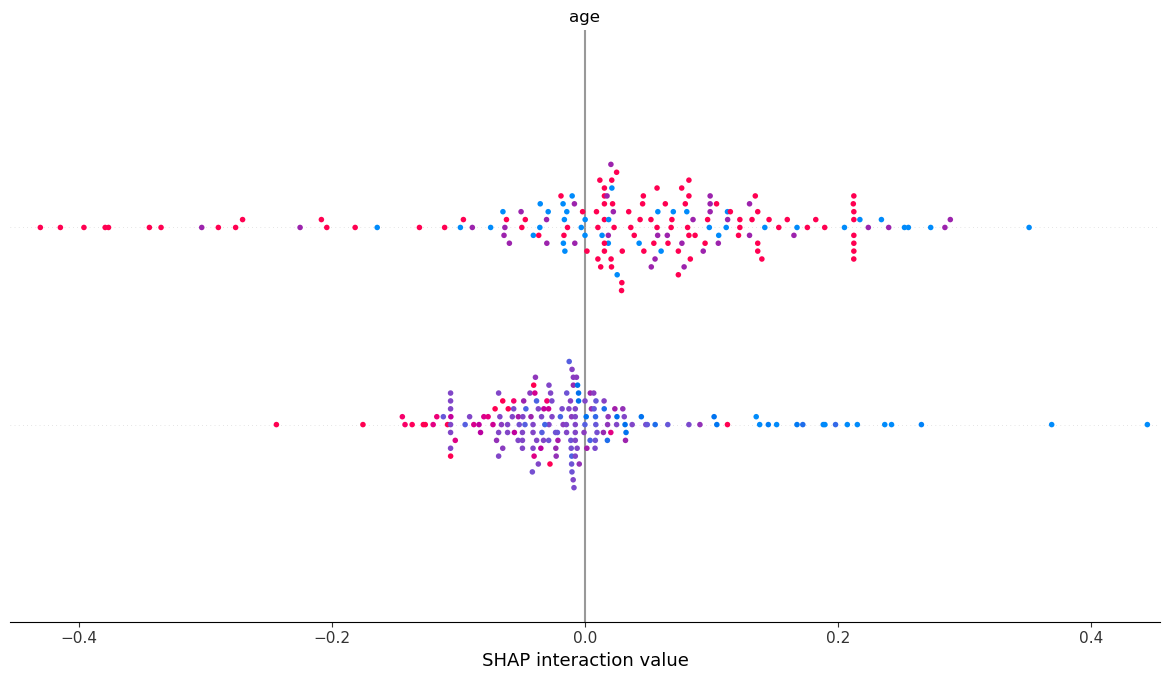

In [61]:
# 전체 피처 중요도 시각화
shap.summary_plot(shap_values, x_test)

In [49]:
rf.feature_importances_

array([0.10049429, 0.24533344, 0.05221748, 0.03595058, 0.25130234,
       0.1394717 , 0.14158896, 0.01284127, 0.00868133, 0.01211861])

In [51]:
x_test.columns

Index(['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_female', 'sex_male',
       'embarked_C', 'embarked_Q', 'embarked_S'],
      dtype='object')

In [82]:
shap_values.values = shap_values.values[:, :, 0]
shap_values.base_values = shap_values.base_values[0,1]

In [84]:
x_test.head(1)

,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
167,3,45.0,1,4,27.9,1,0,0,0,1


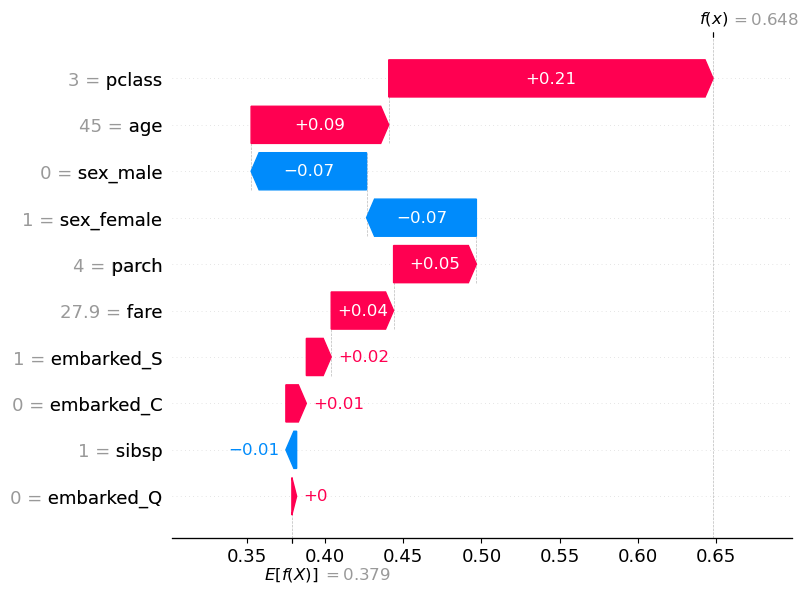

In [83]:
shap.plots.waterfall(shap_values[0])

## lime(fashionMNIST)

In [86]:
# 데이터 불러오기
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [87]:
x_train.shape

(60000, 28, 28)

In [88]:
# 데이터 전처리
scaled_train = x_train.reshape(-1, 28, 28, 1) / 255
scaled_test = x_test.reshape(-1, 28, 28, 1) / 255

In [93]:
# CNN 모델 정의
model = keras.models.Sequential()
model.add(keras.Input(shape = (28, 28, 1)))
model.add(keras.layers.Conv2D(32, 3, activation = "relu"))
model.add(keras.layers.MaxPool2D(2))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(64, activation = "relu"))
model.add(keras.layers.Dropout(0.5))
model.add(keras.layers.Dense(10, activation = "softmax"))

In [94]:
# 모델 학습
model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

In [95]:
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [96]:
model.fit(scaled_train, y_train, epochs = 300, validation_split = 0.2, callbacks = [es_cb])

Epoch 1/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.7024 - loss: 0.8540 - val_accuracy: 0.8712 - val_loss: 0.3626
Epoch 2/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8433 - loss: 0.4529 - val_accuracy: 0.8861 - val_loss: 0.3099
Epoch 3/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.8584 - loss: 0.3954 - val_accuracy: 0.8942 - val_loss: 0.2871
Epoch 4/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.8705 - loss: 0.3562 - val_accuracy: 0.8939 - val_loss: 0.2828
Epoch 5/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.8775 - loss: 0.3344 - val_accuracy: 0.9001 - val_loss: 0.2694
Epoch 6/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8860 - loss: 0.3241 - val_accuracy: 0.9022 - val_loss: 0.2657
Epoch 7/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.8875 - loss: 0.3013 - val_accuracy: 0.9068 - val_loss: 0.2614
Epoch 8/300
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.8938 

In [97]:
# LIME 설명기 준비
explainer = lime_image.LimeImageExplainer()

In [106]:
# LIME용 예측 함수 정의
def predict_fn(images):
    # images = np.array([np.repeat(img[..., np.newaxis], 3, axis = 2) for img in images])
    images_gray = images[..., 0:1]
    return model.predict(images_gray)

In [99]:
# 테스트 이미지 하나 선택
image = x_test[0]

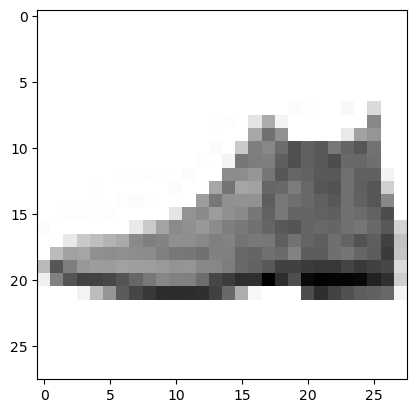

In [100]:
plt.imshow(image, cmap = "gray_r")
plt.show()

In [116]:
explanation = explainer.explain_instance(
    np.squeeze(image), # 입력 이미지
    predict_fn, # 예측 함수
    top_labels = 1,
    hide_color = 0,
    num_samples = 1000
)

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━

In [119]:
# 시각화(예측 클래스에 대해 긍정적으로 기여한 영역)
temp, mask = explanation.get_image_and_mask(
    label = explanation.top_labels[0],
    positive_only = True,
    hide_rest = False
)

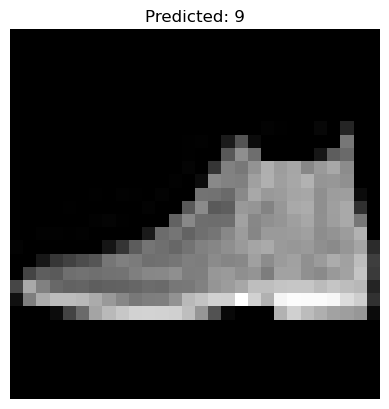

In [120]:
plt.imshow(mark_boundaries(temp / 255, mask))
plt.title(f"Predicted: {explanation.top_labels[0]}")
plt.axis("off")
plt.show()